# Baseline gain $g_0$ with $I = g_0 L^e$, $e = 0.25$

e = 0.25 from the same-spot comparisons of the 4-fish recordings (`EOD_gain_vs_length_4fish_combined.ipynb`). $g_0$ comes from the two
controls, where the emitter is known: the 3-fish recording (2024-10-15, emitter fish 0) and the 2-fish recording (2024-02-13, emitter
fish 1).

My model, BEM conductivities (interior 100 × water, skin 0.05 × water over 0.005 cm), sink at the tail tip, unit current, sign fixed
(× −1); cached pair voltages `u_sink0` and recorded peak patterns `v_rec` (V) of the conductivity runs. For each EOD of the better list
of good frames, the emitter's least-squares gain $g_i = r_i\cdot m_i/\lVert m_i\rVert^2$ (V per model unit), and
$g_{0,i} = g_i / L_\mathrm{em}^{e}$, **L in cm** (L_px / (912 / 60), lengths from `fish_lengths.zeus_lengths`). Units of $g_0$:
V per model unit per cm$^{e}$; with L in tank units ($L_\mathrm{px}/911$) multiply by $(911 / 15.2)^{e}$.

Reported per recording: median of $g_{0,i}$ with a bootstrap 95% interval and the IQR, over all better-list EODs and over the
well-predicted ones (emitter's shape distance ≤ 0.3, patterns scaled to max |v| = 1), and by the pair with the largest recorded
voltage (the gain depends on where the fish is, `EOD_gain_vs_length_4fish_*.ipynb` section 8). Check: the same quantity on the
clear-emitter EODs chosen in the 4-fish recordings (`selected_eods.csv`, each fish divided by its own $L^{e}$).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

E = 0.25
PX_PER_CM = 912 / 60
OUT = 'results/baseline_g0'
import os; os.makedirs(OUT, exist_ok=True)
CONTROLS = {
    '3-fish (2024-10-15)': dict(res='results/eod_ground_truth_3fish', cache='conductivities/model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl',
                                lengths='fish_lengths_3fish.json', emitter=0),
    '2-fish (2024-02-13)': dict(res='results/eod_ground_truth', cache='conductivities/model_voltages_N150_sinks0and0.05_el46ee63_bem_a453a8.pkl',
                                lengths='fish_lengths_2fish.json', emitter=1),
}
unit = lambda x: x / np.abs(x).max(axis=-1, keepdims=True)
rng = np.random.default_rng(0)
def boot_median(x, n=2000):
    return np.percentile([np.median(rng.choice(x, len(x))) for _ in range(n)], [2.5, 97.5])

per_eod, rows = [], []
for name, c in CONTROLS.items():
    cache = pd.read_pickle(f"{c['res']}/{c['cache']}")
    better = cache.frame.isin(pd.read_csv(f"{c['res']}/good_frames_better_list.csv").frame).to_numpy()
    R = np.stack(cache.v_rec.map(np.asarray)); M = -np.stack(cache.u_sink0.map(lambda u: np.asarray(u, float)))[:, c['emitter']]
    ok = better & np.isfinite(M).all(1)
    R, M = R[ok], M[ok]
    L_cm = json.load(open(f"{c['res']}/{c['lengths']}"))['fish'][str(c['emitter'])]['L_px'] / PX_PER_CM
    g = (R * M).sum(1) / (M * M).sum(1)
    d = np.linalg.norm(unit(R) - unit(M), axis=1)
    t = pd.DataFrame({'recording': name, 'g': g, 'g0': g / L_cm ** E, 'd': d, 'pair_max': np.abs(R).argmax(1) + 1, 'L_cm': L_cm})
    per_eod.append(t)
    for sub, m in [('all better-list EODs', np.ones(len(t), bool)), ('well-predicted (d <= 0.3)', t.d <= 0.3)]:
        x = t.g0[m & (t.g0 > 0)].to_numpy(); lo, hi = boot_median(x)
        rows.append({'recording': name, 'EODs': sub, 'n': len(x), 'emitter L (cm)': L_cm, 'median g': np.median(t.g[m]),
                     'g0 = median g / L^e': np.median(x), 'g0 95% low': lo, 'g0 95% high': hi,
                     'IQR low': np.percentile(x, 25), 'IQR high': np.percentile(x, 75), 'g <= 0 (left out)': int((t.g0[m] <= 0).sum())})
EODS = pd.concat(per_eod, ignore_index=True)
G0 = pd.DataFrame(rows).set_index(['recording', 'EODs'])
G0.to_csv(f'{OUT}/g0_controls.csv'); display(G0.round(4))
a = G0.xs('all better-list EODs', level='EODs')
print(f"g0, 3-fish / 2-fish: {a['g0 = median g / L^e'].iloc[0] / a['g0 = median g / L^e'].iloc[1]:.2f}; e that would make one g0 fit both: "
      f"{np.log(a['median g'].iloc[0] / a['median g'].iloc[1]) / np.log(a['emitter L (cm)'].iloc[0] / a['emitter L (cm)'].iloc[1]):.2f}")

n  emitter L (cm)  median g  \
recording           EODs                                                        
3-fish (2024-10-15) all better-list EODs       6694         11.8938    0.9152   
                    well-predicted (d <= 0.3)  1038         11.8938    1.0597   
2-fish (2024-02-13) all better-list EODs       3409         16.4895    0.4925   
                    well-predicted (d <= 0.3)  1423         16.4895    0.5262   

                                               g0 = median g / L^e  \
recording           EODs                                             
3-fish (2024-10-15) all better-list EODs                    0.4938   
                    well-predicted (d <= 0.3)               0.5706   
2-fish (2024-02-13) all better-list EODs                    0.2474   
                    well-predicted (d <= 0.3)               0.2611   

                                               g0 95% low  g0 95% high  \
recording           EODs                                                 
3-fish (2024-10-15) all better-list EODs           0.4906       0.4969   
                    well-predicted (d <= 0.3)      0.5610       0.5794   
2-fish (2024-02-13) all better-list EODs           0.2436       0.2502   
                    well-predicted (d <= 0.3)      0.2570       0.2655   

                                               IQR low  IQR high  \
recording           EODs                                           
3-fish (2024-10-15) all better-list EODs        0.4237    0.5777   
                    well-predicted (d <= 0.3)   0.4990    0.6731   
2-fish (2024-02-13) all better-list EODs        0.1859    0.3092   
                    well-predicted (d <= 0.3)   0.2252    0.3086   

                                               g <= 0 (left out)  
recording           EODs                                          
3-fish (2024-10-15) all better-list EODs                      57  
                    well-predicted (d <= 0.3)                  0  
2-fish (2024-02-13) all better-list EODs                      92  
                    well-predicted (d <= 0.3)                  0

g0, 3-fish / 2-fish: 2.00; e that would make one g0 fit both: -1.90


### By the pair with the largest recorded voltage (well-predicted EODs)

In [2]:
byp = EODS[EODS.d <= 0.3].pivot_table(index='pair_max', columns='recording', values='g0', aggfunc=['median', 'size'])
byp.to_csv(f'{OUT}/g0_controls_by_pair.csv'); display(byp.round(3))

median                                    size  \
recording 2-fish (2024-02-13) 3-fish (2024-10-15) 2-fish (2024-02-13)   
pair_max                                                                
1                       0.210               0.487               117.0   
2                       0.172                 NaN                61.0   
3                       0.177               0.731                29.0   
4                       0.182               0.473                58.0   
5                       0.220               0.588                12.0   
6                       0.318               0.589               347.0   
7                       0.286               0.712               389.0   
8                       0.242               0.668               231.0   
9                       0.235               0.507               154.0   
10                      0.337               0.588                25.0   

                               
recording 3-fish (2024-10-15)  
pair_max                       
1                        46.0  
2                         NaN  
3                         2.0  
4                         9.0  
5                        21.0  
6                        35.0  
7                       203.0  
8                        81.0  
9                       392.0  
10                      249.0

### Check: the 4-fish recordings

Clear-emitter EODs near an electrode chosen in `EOD_gain_vs_length_4fish_<recording>.ipynb` (section 5), $g_{0,i} = a_i / L_f^{e}$ with
each fish's own length.

In [3]:
rows4 = []
for rec in ['2024-02-20T21_16_26', '2024-02-20T18_16_24', '2024-10-23T15_18_28']:
    s = pd.read_csv(f'results/eod_gain_4fish/{rec}/selected_eods.csv')
    j = json.load(open(f'results/eod_gain_4fish/{rec}/fish_lengths_4fish.json'))
    L = np.array([j['fish'][str(f)]['L_px'] / j['px_per_cm'] for f in range(4)])
    s['g0'] = s.gain_ls / L[s.fish] ** E
    for f, q in s.groupby('fish'):
        rows4.append({'recording': rec, 'fish': 'ABCD'[f], 'L (cm)': L[f], 'n': len(q), 'median g0': q.g0.median()})
    lo, hi = boot_median(s.g0.to_numpy())
    rows4.append({'recording': rec, 'fish': 'all', 'L (cm)': np.nan, 'n': len(s), 'median g0': s.g0.median(), '95% low': lo, '95% high': hi})
G4 = pd.DataFrame(rows4); G4.to_csv(f'{OUT}/g0_4fish_check.csv', index=False); display(G4.round(4))

,recording,fish,L (cm),n,median g0,95% low,95% high
0,2024-02-20T21_16_26,A,14.7426,10,0.2604,NaN,NaN
1,2024-02-20T21_16_26,B,12.9514,10,0.1416,NaN,NaN
2,2024-02-20T21_16_26,C,9.3607,5,0.3192,NaN,NaN
3,2024-02-20T21_16_26,D,8.1813,7,0.1684,NaN,NaN
4,2024-02-20T21_16_26,all,NaN,32,0.1763,0.1604,0.2549
5,2024-02-20T18_16_24,A,14.4036,10,0.2744,NaN,NaN
6,2024-02-20T18_16_24,B,12.8508,10,0.1380,NaN,NaN
7,2024-02-20T18_16_24,C,9.1716,8,0.3146,NaN,NaN
8,2024-02-20T18_16_24,D,8.2593,2,0.2419,NaN,NaN
9,2024-02-20T18_16_24,all,NaN,30,0.2304,0.1648,0.2911


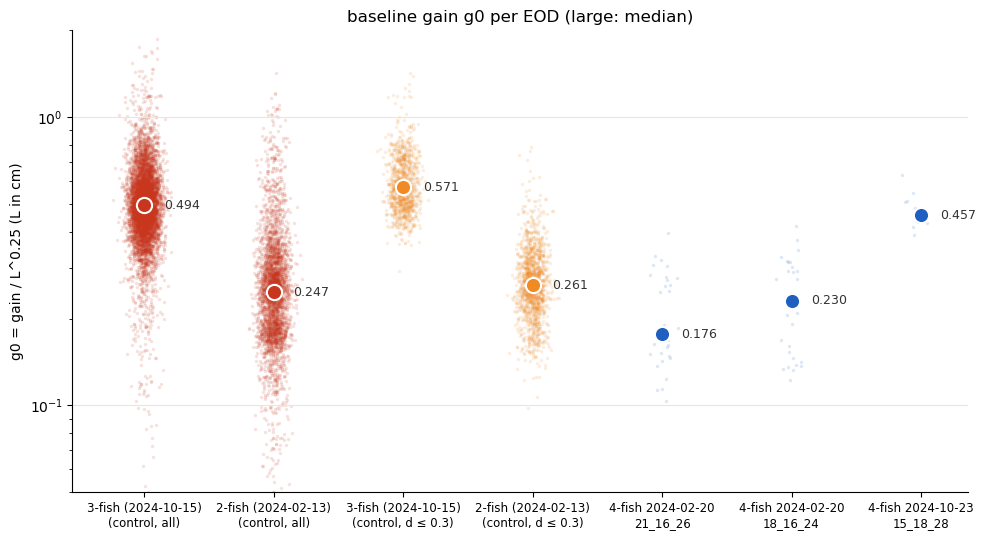

In [4]:
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(10, 5.5))
items = [(f'{n}\n(control, all)', EODS[EODS.recording == n].g0, '#C8361E') for n in CONTROLS]
items += [(f'{n}\n(control, d ≤ 0.3)', EODS[(EODS.recording == n) & (EODS.d <= 0.3)].g0, '#F08A24') for n in CONTROLS]
for rec in ['2024-02-20T21_16_26', '2024-02-20T18_16_24', '2024-10-23T15_18_28']:
    s = pd.read_csv(f'results/eod_gain_4fish/{rec}/selected_eods.csv'); j = json.load(open(f'results/eod_gain_4fish/{rec}/fish_lengths_4fish.json'))
    L = np.array([j['fish'][str(f)]['L_px'] / j['px_per_cm'] for f in range(4)])
    items.append((f'4-fish {rec[:10]}\n{rec[11:]}', s.gain_ls / L[s.fish] ** E, '#1F5FBF'))
for k, (lab, x, col) in enumerate(items):
    x = x[x > 0]
    ax.scatter(k + rng.normal(0, 0.06, len(x)), x, s=6, color=col, alpha=0.15, lw=0)
    ax.scatter(k, np.median(x), s=120, color=col, edgecolor='white', lw=1.5, zorder=3)
    ax.text(k + 0.15, np.median(x), f'{np.median(x):.3f}', va='center', fontsize=9, color='0.2')
ax.set(yscale='log', ylim=(0.05, 2), ylabel='g0 = gain / L^0.25 (L in cm)', xticks=range(len(items)), title='baseline gain g0 per EOD (large: median)')
ax.set_xticklabels([i[0] for i in items], fontsize=8.5); ax.grid(True, axis='y', color='#e6e6e3')
plt.tight_layout(); fig.savefig(f'{OUT}/g0_per_recording.png', dpi=120); plt.show()